# 01 — CT preprocessing and series selection

Exploratory notebook for the DICOM → model-ready volume stage on the NSCLC-Radiogenomics CT scans.

1. Single-patient walkthrough: DICOM → Hounsfield units, 1 mm isotropic resampling, body ROI crop, HU windowing/normalisation to [0, 1], resize to 128³.
2. Inspection of the series available per patient (PET, scout, coronal/sagittal and fusion series sit next to the diagnostic chest CT).
3. Rule-based series selection (keyword penalties/priorities + slice thickness + slice count). The scoring function in the later cells supersedes the simple "most slices" rule used in the first cells.
4. Dimension / voxel-size summary of all 211 patients.

Paths are Windows paths from the original machine (`D:\\NSCLC_PROJECT\\...`); change the path constants at the top of each notebook before running. Raw data and model weights are **not** included in this repository.

In [2]:
import os
import pydicom
import numpy as np
import SimpleITK as sitk
from typing import Tuple, Optional


BASE_DATA_DIR = r"D:\NSCLC_PROJECT\raw-zip\NSCLC-Radiogenomics" 
patient_id = "AMC-001"
patient_folder = os.path.join(BASE_DATA_DIR, patient_id)

print(f"searching: {patient_id}")

def find_main_ct_folder(root_folder):
    dicom_series_folder = None
    max_slices = 0
    
    # بیشترین اسلایس
    for root, dirs, files in os.walk(root_folder):
        # حذف پوشه‌هایی که کلمه SCOUT دارند برای امنیت بیشتر
        if "scout" in root.lower():
            continue
            
        dcm_files = [f for f in files if f.lower().endswith('.dcm')]
        
        # انتخاب پوشه ای که بیشترین اسلایس را دارد
        if len(dcm_files) > max_slices:
            max_slices = len(dcm_files)
            dicom_series_folder = root
            return dicom_series_folder
            
    if dicom_series_folder is None or max_slices <= 1:
        raise FileNotFoundError(f"3D folder is not found.")
    
    print(f"Main CT series found: {dicom_series_folder}")
    print(f"Total slices detected: {max_slices}")
    
    # لود کردن سری تصاویر
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(dicom_series_folder)
    reader.SetFileNames(dicom_names)
    image_3d = reader.Execute()
    
    # تبدیل به آرایه عددی
    volume_array = sitk.GetArrayFromImage(image_3d)
    
    # اعمال فرمول هانسفیلد (HU)
    sample_slice = pydicom.dcmread(dicom_names[0])
    slope = getattr(sample_slice, 'RescaleSlope', 1.0)
    intercept = getattr(sample_slice, 'RescaleIntercept', -1024.0)
    
    hu_volume = (volume_array * slope) + intercept
    
    return hu_volume, image_3d

# اجرا
try:
    hu_pixels, original_sitk_image = find_main_ct_folder(patient_folder)
    print("\n--- Step 1: Data Ingestion & HU Conversion Completed Successfully ---")
    print(f"3D Volume Shape (Slices, Height, Width): {hu_pixels.shape}")
    print(f" Minimum Intensity: {np.min(hu_pixels)} HU")
    print(f"Maximum Intensitty: {np.max(hu_pixels)} HU")
except Exception as e:
    print(f"❌ Error encountered: {e}")

In [ ]:
def resample_image(sitk_image, new_spacing=[1.0, 1.0, 1.0]):
    # ۱. خواندن اسپیسینگ (فاصله فیزیکی پیکسل‌های) فعلی بیمار
    original_spacing = sitk_image.GetSpacing()
    original_size = sitk_image.GetSize()
    
    # ۲. محاسبه داینامیک ابعاد جدید تصویر بر اساس نسبت اسپیسینگ‌ها
    new_size = [
        int(round(original_size[0] * original_spacing[0] / new_spacing[0])),
        int(round(original_size[1] * original_spacing[1] / new_spacing[1])),
        int(round(original_size[2] * original_spacing[2] / new_spacing[2]))
    ]
    
    # ۳.resampleimagefilter
    resample = sitk.ResampleImageFilter()
    resample.SetInterpolator(sitk.sitkLinear) # استفاده از اینترپولیشن خطی
    resample.SetOutputSpacing(new_spacing)
    resample.SetSize(new_size)
    resample.SetOutputDirection(sitk_image.GetDirection())
    resample.SetOutputOrigin(sitk_image.GetOrigin())
    resample.SetTransform(sitk.Transform())
    
    # مقدار پیش‌فرض برای نواحی خالی بیرون بدن (هوای شدیدا سرد)
    resample.SetDefaultPixelValue(-1024) 
    
    return resample.Execute(sitk_image)

# اجرای گام دوم روی بیمار اول
try:
    print(f"original volume spacing: {original_sitk_image.GetSpacing()}")
    
    # انجام ریسمپلینگ
    resampled_sitk_image = resample_image(original_sitk_image, new_spacing=[1.0, 1.0, 1.0])
    resampled_hu_pixels = sitk.GetArrayFromImage(resampled_sitk_image)
    
    print("\n--- Step 2: Spatial Resampling Completed Successfully ---")
    print(f" New Volume Shape (Slices, Height, Width): {resampled_hu_pixels.shape}")
    print(f"New Volume Spacing: {resampled_sitk_image.GetSpacing()}")
except Exception as e:
    print(f"Error encountered during resampling: {e}")

اسپیسینگ اصلی بیمار اول: (0.976562, 0.976562, 3.27)

--- گام دوم با موفقیت انجام شد! ---
ابعاد تصویر بعد از همسان‌سازی (Resampling): (860, 500, 500)
اسپیسینگ جدید تصویر: (1.0, 1.0, 1.0)


In [ ]:
def extract_roi_bounding_box(hu_array, threshold: float = -500.0):
    # ۱. پیدا کردن تمام پیکسل‌هایی که داخل بدن بیمار هستند (بزرگتر از ۵۰۰-)
    # مقادیر کمتر از ۵۰۰- معمولاً هوای بیرون بدن هستند
    body_mask = hu_array > threshold
    
    # ۲. پیدا کردن مختصات (اندیس‌های) جاهایی که بدن بیمار قرار دارد
    z_indices, y_indices, x_indices = np.where(body_mask)
    
    # ۳. پیدا کردن کمترین و بیشترین مرز در هر ۳ محور (ساخت جعبه محدودکننده)
    min_z, max_z = np.min(z_indices), np.max(z_indices)
    min_y, max_y = np.min(y_indices), np.max(y_indices)
    min_x, max_x = np.min(x_indices), np.max(x_indices)
    
    # اضافه کردن یک حاشیه کوچک (Padding) برای اینکه لبه‌های ریه قطع نشوند
    padding = 5
    min_z = max(0, min_z - padding)
    max_z = min(hu_array.shape[0], max_z + padding)
    min_y = max(0, min_y - padding)
    max_y = min(hu_array.shape[1], max_y + padding)
    min_x = max(0, min_x - padding)
    max_x = min(hu_array.shape[2], max_x + padding)
    
    # ۴. کراپ کردن (بریدن) تصویر اصلی بر اساس مرزهای پیدا شده
    cropped_hu = hu_array[min_z:max_z, min_y:max_y, min_x:max_x]
    
    return cropped_hu, (min_z, max_z, min_y, max_y, min_x, max_x)

# اجرای گام سوم روی خروجی گام دوم
try:
    print(f"Volume shape before ROI cropping(ROI): {resampled_hu_pixels.shape}")
    
    cropped_hu_pixels, bounding_box = extract_roi_bounding_box(resampled_hu_pixels)
    
    print("\n--- Step 3: ROI Bounding Box Extraction Completed Successfully ---")
    print(f"Extracted Bounding Box Coordinates (Z_min, Z_max, Y_min, Y_max, X_min, X_max): {bounding_box}")
    print(f"Final Volume Shape after eliminating empty background space: {cropped_hu_pixels.shape}")
except Exception as e:
    print(f" Error encountered during cropping: {e}")

ابعاد تصویر قبل از کراپ کردن (ROI): (860, 500, 500)

--- گام سوم با موفقیت انجام شد! ---
مرزهای جعبه قفسه سینه (Z, Y, X): (0, 860, np.int64(108), np.int64(450), 0, 500)
ابعاد تصویر نهایی بعد از حذف فضاهای اضافی: (860, 342, 500)


In [ ]:
def normalize_hu(hu_array, min_hu=-1000.0, max_hu=400.0):
    # ۱. اعمال پنجره‌گذاری (Windowing)
    clipped_hu = np.clip(hu_array, min_hu, max_hu)
    
    # ۲. فرمول Min-Max  [0, 1]
    normalized_hu = (clipped_hu - min_hu) / (max_hu - min_hu)
    
    return normalized_hu

# step4
try:
    print(f"Intensity range before normalization:{np.min(cropped_hu_pixels)} تا {np.max(cropped_hu_pixels)} HU")
    
    normalized_pixels = normalize_hu(cropped_hu_pixels, min_hu=-1000.0, max_hu=400.0)
    
    print("\n--- Step 4: Intensity Windowing & Normalization Completed Successfully ---")
    print(f"Volume Shape (Unchanged): {normalized_pixels.shape}")
    print(f"New Minimum Intensity Value: {np.min(normalized_pixels)}")
    print(f"New Maximum Intensity Value: {np.max(normalized_pixels)}")
except Exception as e:
    print(f"Error encountered during normalization: {e}")

بازه عددی قبل از نرمال‌سازی: از -3024 تا 3071 HU

--- گام چهارم با موفقیت انجام شد! ---
ابعاد تصویر (بدون تغییر): (860, 342, 500)
کمترین مقدار عددی جدید در تصویر: 0.0
بیشترین مقدار عددی جدید در تصویر: 1.0


In [1]:
import torch
import torch.nn.functional as F

def resize_volume_3d(tensor_array, target_shape=(128, 128, 128)):
    # 1. تبدیل آرایه به تنشور پایتورچ
    # ابعاد ورودی را به فرمت استاندارد پایتورچ (Batch, Channel, Depth, Height, Width) می‌بریم
    tensor = torch.from_numpy(tensor_array).float().unsqueeze(0).unsqueeze(0)
    
    # ۲. استفاده از الگوریتم درایور سه بعدی (Trilinear) برای تغییر سایز هوشمند
    resized_tensor = F.interpolate(tensor, size=target_shape, mode='trilinear', align_corners=False)
    
    # ۳. برگرداندن به شکل یک آرایه معمولی
    output_array = resized_tensor.squeeze(0).squeeze(0).numpy()
    
    return output_array

# step5
try:
    print(f"Volume shape before final uniform resizing: {normalized_pixels.shape}")
    
    # تغییر سایز به ابعاد استاندارد ۱۲۸ در ۱۲۸ در ۱۲۸
    final_processed_volume = resize_volume_3d(normalized_pixels, target_shape=(128, 128, 128))
    
    print("\n--- Step 5: Final Cubical Resizing Completed Successfully! ---")
    print(f"Final standardized tensor shape: {final_processed_volume.shape}")
    print(f" Final normalized intensity bounds: {np.min(final_processed_volume)} to {np.max(final_processed_volume)}")
except Exception as e:
    print(f"Error encountered during final resizing: {e}")

In [ ]:
import os
import pydicom
import numpy as np
import SimpleITK as sitk
import torch
import torch.nn.functional as F

BASE_DATA_DIR = r"D:\NSCLC_PROJECT\raw-zip\NSCLC-Radiogenomics"
OUTPUT_DIR = r"D:\NSCLC_PROJECT\processed_data"
PROBLEM_PATIENT = "R01-039"

patient_path = os.path.join(BASE_DATA_DIR, PROBLEM_PATIENT)

print("STEP1...")
def find_main_ct_folder(root_folder):
    for root, dirs, files in os.walk(root_folder):
        if "scout" in root.lower(): continue
        dcm_files = [f for f in files if f.lower().endswith('.dcm')]
        if len(dcm_files) > 0: return root
    return None

ct_folder = find_main_ct_folder(patient_path)
reader = sitk.ImageSeriesReader()
dicom_names = reader.GetGDCMSeriesFileNames(ct_folder)
reader.SetFileNames(dicom_names)
image_3d = reader.Execute()
volume_array = sitk.GetArrayFromImage(image_3d)

# اصلاح اول: اگر ابعاد ۴بعدی بود و بعد اول ۱ بود، آن را حذف می‌کنیم تا ۳بعدی شود
if volume_array.ndim == 4 and volume_array.shape[0] == 1:
    volume_array = np.squeeze(volume_array, axis=0)

sample_slice = pydicom.dcmread(dicom_names[0])
slope = getattr(sample_slice, 'RescaleSlope', 1.0)
intercept = getattr(sample_slice, 'RescaleIntercept', -1024.0)
hu_volume = (volume_array * slope) + intercept
print(f"STEP1 COMPLETED: {hu_volume.shape}")

print("STEP2...")
def resample_image(sitk_image, new_spacing=[1.0, 1.0, 1.0]):
    original_spacing, original_size = sitk_image.GetSpacing(), sitk_image.GetSize()
    new_size = [int(round(original_size[i] * original_spacing[i] / new_spacing[i])) for i in range(3)]
    resample = sitk.ResampleImageFilter()
    resample.SetInterpolator(sitk.sitkLinear)
    resample.SetOutputSpacing(new_spacing)
    resample.SetSize(new_size)
    
    try:
        resample.SetOutputDirection(sitk_image.GetDirection())
    except:
        resample.SetOutputDirection([1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0])
        
    resample.SetOutputOrigin(sitk_image.GetOrigin())
    resample.SetTransform(sitk.Transform())
    resample.SetDefaultPixelValue(-1024)
    return resample.Execute(sitk_image)

sitk_image = sitk.GetImageFromArray(hu_volume)
sitk_image.SetSpacing(image_3d.GetSpacing()[:3])  # فقط ۳ بعد اول اسپیسینگ را برمی‌داریم
sitk_image.SetOrigin(image_3d.GetOrigin()[:3])

try:
    if len(image_3d.GetDirection()) == 9:
        sitk_image.SetDirection(image_3d.GetDirection())
    else:
        sitk_image.SetDirection([1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0])
except:
    sitk_image.SetDirection([1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0])

resampled_array = sitk.GetArrayFromImage(resample_image(sitk_image))
print(f"STEP2 COMPLETED: {resampled_array.shape}")

print("STEP3...")
def extract_roi_bounding_box_low_mem(hu_array, threshold=-500):
    z_mask = np.any(hu_array > threshold, axis=(1, 2))
    if not np.any(z_mask): return hu_array
    min_z, max_z = np.where(z_mask)[0][0], np.where(z_mask)[0][-1]
    
    active_volume = hu_array[min_z:max_z+1]
    y_mask = np.any(active_volume > threshold, axis=(0, 2))
    x_mask = np.any(active_volume > threshold, axis=(0, 1))
    
    min_y, max_y = np.where(y_mask)[0][0], np.where(y_mask)[0][-1]
    min_x, max_x = np.where(x_mask)[0][0], np.where(x_mask)[0][-1]
    
    padding = 5
    min_z = max(0, min_z - padding)
    max_z = min(hu_array.shape[0], max_z + padding)
    min_y = max(0, min_y - padding)
    max_y = min(hu_array.shape[1], max_y + padding)
    min_x = max(0, min_x - padding)
    max_x = min(hu_array.shape[2], max_x + padding)
    return hu_array[min_z:max_z, min_y:max_y, min_x:max_x]

cropped_array = extract_roi_bounding_box_low_mem(resampled_array)
print(f"STEP3 COMPLETED: {cropped_array.shape}")

print("STEP4,5...")
normalized_array = (np.clip(cropped_array, -1000.0, 400.0) - (-1000.0)) / 1400.0

# اینجا آرایه دقیقاً ۳بعدی است، پس با دو بار unsqueeze دقیقاً ۵بعدیِ استاندارد پایتورچ می‌شود
tensor = torch.from_numpy(normalized_array).float().unsqueeze(0).unsqueeze(0)
final_volume = F.interpolate(tensor, size=(128, 128, 128), mode='trilinear', align_corners=False).squeeze().numpy()

output_file_path = os.path.join(OUTPUT_DIR, f"{PROBLEM_PATIENT}.npy")
np.save(output_file_path, final_volume)
print(f"Success! Patient {PROBLEM_PATIENT} has been successfully processed and synchronized with the dataset.")

⏳ گام ۱: در حال پیدا کردن پوشه و خواندن فایل‌های DICOM...
✅ گام ۱ با موفقیت انجام شد. ابعاد ماتریس هانسفیلد اصلاح‌شده: (125, 512, 512)
⏳ گام ۲: در حال انجام Resampling به ابعاد فیزیکی 1.0mm...
✅ گام ۲ با موفقیت انجام شد. ابعاد پس از ریسمپلینگ: (312, 400, 400)
⏳ گام ۳: در حال کراپ کردن هوشمند (ROI)...
✅ گام ۳ با موفقیت انجام شد. ابعاد پس از کراپ: (312, 400, 400)
⏳ گام ۴ و ۵: نرمال‌سازی و ری‌سایز نهایی...
🎉 فوق‌العاده است! آخرین بیمار (R01-039) با موفقیت ۱۰۰٪ پردازش و ذخیره شد.


شکل داده (Shape): (128, 128, 128)


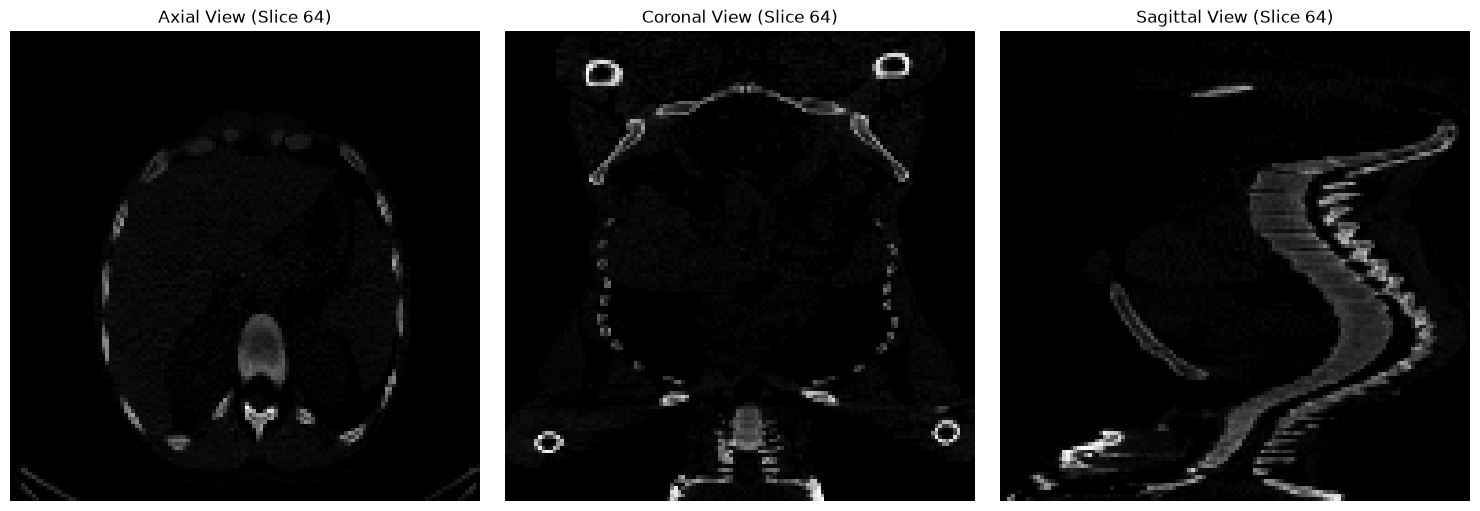

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os

# ۱. مسیر یکی از فایل‌های پردازش‌شده را وارد کن
# اگر فایل‌ها در فولدر پروژه هستند، نام یکی را دقیقاً بگذار
file_path = r'D:\NSCLC_PROJECT\raw-zip\process_data\AMC-001.npy'  # مسیر نمونه را در صورت نیاز تغییر بده

if os.path.exists(file_path):
    # بارگذاری داده ۳ بعدی
    volume = np.load(file_path)
    print(f"شکل داده (Shape): {volume.shape}")
    
    # پیدا کردن اسلایس‌های مرکز حجم (به عنوان مثال اسلایس ۶۴ از ۱۲۸)
    mid_z = volume.shape[0] // 2
    mid_y = volume.shape[1] // 2
    mid_x = volume.shape[2] // 2

    # رسم ۳ نما
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # نمای Axial (از بالا/افقی)
    axes[0].imshow(volume[mid_z, :, :], cmap='gray')
    axes[0].set_title(f'Axial View (Slice {mid_z})')
    axes[0].axis('off')

    # نمای Coronal (از روبرو)
    axes[1].imshow(volume[:, mid_y, :], cmap='gray')
    axes[1].set_title(f'Coronal View (Slice {mid_y})')
    axes[1].axis('off')

    # نمای Sagittal (از کنار)
    axes[2].imshow(volume[:, :, mid_x], cmap='gray')
    axes[2].set_title(f'Sagittal View (Slice {mid_x})')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("خطا: فایل یافت نشد! لطفاً آدرس دقیق فایل .npy را بررسی کن.")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

# آدرس پوشه داده‌ها و پوشه ذخیره خروجی عکس‌ها
folder_path = r'D:\NSCLC_PROJECT\raw-zip\process_data'
save_folder = r'D:\NSCLC_PROJECT\sample_plots'
os.makedirs(save_folder, exist_ok=True)

# گرفتن لیست فایل‌های npy
npy_files = [f for f in os.listdir(folder_path) if f.endswith('.npy')]

# تولید عکس برای ۵ بیمار اول جهت ارائه در گزارش پروژه
for i, file_name in enumerate(npy_files[:5]):
    file_path = os.path.join(folder_path, file_name)
    volume = np.load(file_path)
    
    mid_z = volume.shape[0] // 2
    mid_y = volume.shape[1] // 2
    mid_x = volume.shape[2] // 2

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    axes[0].imshow(volume[mid_z, :, :], cmap='gray')
    axes[0].set_title(f'Axial View (Slice {mid_z})')
    axes[0].axis('off')

    axes[1].imshow(volume[:, mid_y, :], cmap='gray')
    axes[1].set_title(f'Coronal View (Slice {mid_y})')
    axes[1].axis('off')

    axes[2].imshow(volume[:, :, mid_x], cmap='gray')
    axes[2].set_title(f'Sagittal View (Slice {mid_x})')
    axes[2].axis('off')

    plt.suptitle(f'Patient Sample: {file_name}', fontsize=14)
    plt.tight_layout()
    
    # ذخیره تصویر با کیفیت بالا
    save_path = os.path.join(save_folder, f'{file_name[:-4]}_views.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close()

print(f"عکس‌های نمونه با موفقیت در پوشه {save_folder} ذخیره شدند!")

فایل‌های DICOM پیدا شدند در مسیر:
D:\NSCLC_PROJECT\raw-zip\NSCLC-Radiogenomics\AMC-001\04-30-1994-NA-PETCT Lung Cancer-74760\3.000000-CT FUSION-97864
تعداد اسلایس‌های بارگذاری شده: 263


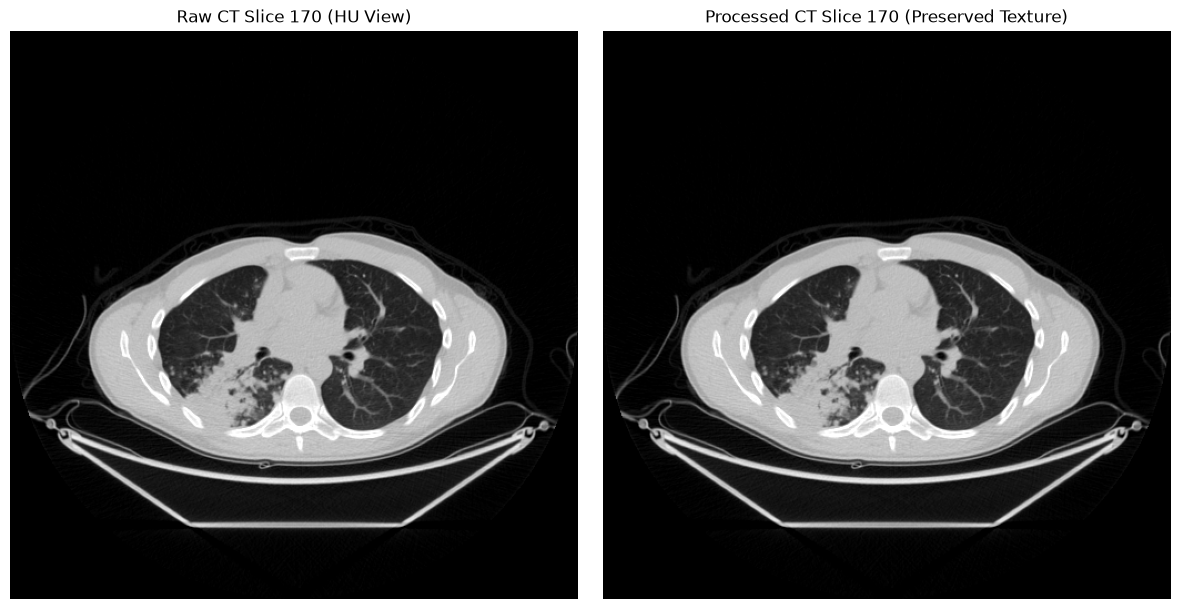

<Figure size 640x480 with 0 Axes>

In [9]:
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
import os

def load_patient_dicom_auto(patient_root_folder):
    """
    جستجوی خودکار عمیق برای یافتن سری DICOM اصلی در پوشه‌های چندلایه TCIA
    """
    reader = sitk.ImageSeriesReader()
    
    # اول بررسی می‌کنیم آیا در خود همین مسیر فایل هست یا نه
    series_ids = reader.GetGDCMSeriesIDs(patient_root_folder)
    
    # اگر نبود، تمام زیرپوشه‌ها را برای پیدا کردن فایل‌های DICOM می‌گردیم
    if not series_ids:
        for root, dirs, files in os.walk(patient_root_folder):
            ids = reader.GetGDCMSeriesIDs(root)
            if ids:
                # بزرگ‌ترین سری را پیدا می‌کنیم (معمولاً سری اصلی CT قفسه سینه بیشترین اسلایس را دارد)
                dicom_names = reader.GetGDCMSeriesFileNames(root, ids[0])
                if len(dicom_names) > 30: # سری اصلی CT معمولا بیش از ۳۰ اسلایس دارد
                    reader.SetFileNames(dicom_names)
                    image_3d = reader.Execute()
                    print(f"فایل‌های DICOM پیدا شدند در مسیر:\n{root}")
                    print(f"تعداد اسلایس‌های بارگذاری شده: {len(dicom_names)}")
                    return sitk.GetArrayFromImage(image_3d)
                    
    elif series_ids:
        dicom_names = reader.GetGDCMSeriesFileNames(patient_root_folder, series_ids[0])
        reader.SetFileNames(dicom_names)
        image_3d = reader.Execute()
        return sitk.GetArrayFromImage(image_3d)
        
    raise ValueError("هیچ سری DICOM معتبری در این پوشه پیدا نشد!")

def preprocess_lung_ct(ct_volume, hu_min=-1000.0, hu_max=400.0):
    # تنظیم محدوده پنجره ریه (Lung Window)
    windowed = np.clip(ct_volume, hu_min, hu_max)
    # نرمال‌سازی بین 0 و 1
    normalized = (windowed - hu_min) / (hu_max - hu_min)
    return normalized.astype(np.float32)

# ---------------------------------------------------------
# آدرس اصلی پوشه بیمار AMC-001 (بدون نیاز به رفتن به زیرپوشه‌ها!)
patient_folder = r"D:\NSCLC_PROJECT\raw-zip\NSCLC-Radiogenomics" 

# اجرای کد
raw_ct = load_patient_dicom_auto(patient_folder)
processed_ct = preprocess_lung_ct(raw_ct)

# نمایش اسلایس میانی بافت ریه
# به جای وسط حجم، اسلایسی را می‌بینیم که ریه‌ها در آن هستند (مثلاً اسلایس 60٪ یا 70٪)
lung_slice_idx = int(raw_ct.shape[0] * 0.65)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(raw_ct[lung_slice_idx], cmap='gray', vmin=-1000, vmax=400)
axes[0].set_title(f"Raw CT Slice {lung_slice_idx} (HU View)")
axes[0].axis('off')

axes[1].imshow(processed_ct[lung_slice_idx], cmap='gray')
axes[1].set_title(f"Processed CT Slice {lung_slice_idx} (Preserved Texture)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

plt.tight_layout()
os.makedirs(r"D:\NSCLC_PROJECT\sample_plots", exist_ok=True)
plt.savefig(r"D:\NSCLC_PROJECT\sample_plots\correct_preprocessing_proof.png", dpi=300)
plt.show()

In [5]:
import os
import SimpleITK as sitk

# آدرس پوشه اصلی دیتاست
DATASET_PATH = r"D:\NSCLC_PROJECT\raw-zip\NSCLC-Radiogenomics"

def inspect_first_patient_metadata(dataset_path):
    all_patients = [p for p in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, p))]
    if not all_patients:
        print("پوشه‌ای پیدا نشد.")
        return
    
    first_patient = all_patients[0]
    patient_path = os.path.join(dataset_path, first_patient)
    print(f"=== در حال بررسی متادیتای کامل برای بیمار: {first_patient} ===\n")

    for root, dirs, files in os.walk(patient_path):
        dcm_files = [f for f in files if f.lower().endswith('.dcm')]
        if not dcm_files:
            continue
            
        try:
            sample_file = os.path.join(root, dcm_files[0])
            reader = sitk.ImageFileReader()
            reader.SetFileName(sample_file)
            reader.ReadImageInformation()
            
            modality = reader.GetMetaData('0008|0600') if reader.HasMetaDataKey('0008|0600') else 'N/A'
            series_desc = reader.GetMetaData('0008|103e') if reader.HasMetaDataKey('0008|103e') else 'N/A'
            
            if reader.HasMetaDataKey('0018|0050'):
                thickness = float(reader.GetMetaData('0018|0050'))
            else:
                thickness = float(reader.GetSpacing()[2])

            print(f"پوشه: {os.path.basename(root)}")
            print(f"  ├─ Modality: {modality.strip()}")
            print(f"  ├─ Series Description: {series_desc.strip()}")
            print(f"  ├─ Slice Thickness: {thickness:.2f} mm")
            print(f"  └─ Total Slices: {len(dcm_files)}")
            print("-" * 60)

        except Exception as e:
            print(f"خطا در خواندن پوشه {root}: {e}")

inspect_first_patient_metadata(DATASET_PATH)

=== در حال بررسی متادیتای کامل برای بیمار: AMC-001 ===

پوشه: 1.000000-SCOUT-96085
  ├─ Modality: N/A
  ├─ Series Description: SCOUT
  ├─ Slice Thickness: 1200.55 mm
  └─ Total Slices: 1
------------------------------------------------------------
پوشه: 3.000000-CT FUSION-97864
  ├─ Modality: N/A
  ├─ Series Description: CT FUSION
  ├─ Slice Thickness: 3.75 mm
  └─ Total Slices: 263
------------------------------------------------------------
پوشه: 6.000000-WB MAC P690-69577
  ├─ Modality: N/A
  ├─ Series Description: WB MAC P690
  ├─ Slice Thickness: 3.27 mm
  └─ Total Slices: 263
------------------------------------------------------------
پوشه: 7.000000-WB NAC P690-00278
  ├─ Modality: N/A
  ├─ Series Description: WB NAC P690
  ├─ Slice Thickness: 3.27 mm
  └─ Total Slices: 263
------------------------------------------------------------
پوشه: 3.000000-CHEST 1.25 MM SHARP-51907
  ├─ Modality: N/A
  ├─ Series Description: CHEST 1.25 MM SHARP
  ├─ Slice Thickness: 1.25 mm
  └─ Total S

In [20]:
import os
import pydicom

# مسیر مستقیم پوشه بیمار R01-158 رو اینجا بذار
patient_158_path = r"D:\NSCLC_PROJECT\raw-zip\NSCLC-Radiogenomics\R01-158" 

print(f"ررسی دقیق تمام سری‌ها و فایل‌های بیمار R01-158 ---")
found_any = False

for root, dirs, files in os.walk(patient_158_path):
    # پیدا کردن فایل‌های دایکام
    dicom_files = [f for f in files if f.endswith('.dcm') or not '.' in f]
    
    if dicom_files:
        found_any = True
        sample_file = os.path.join(root, dicom_files[0])
        try:
            ds = pydicom.dcmread(sample_file, stop_before_pixels=True)
            desc = getattr(ds, 'SeriesDescription', 'NO_DESCRIPTION')
            modality = getattr(ds, 'Modality', 'UNKNOWN')
            thickness = getattr(ds, 'SliceThickness', 'UNKNOWN')
            
            print(f"\n📂 Folder: {root}")
            print(f" ├── Slice Count: {len(dicom_files)}")
            print(f" ├── Series Description: {desc}")
            print(f" ├── Modality: {modality}")
            print(f" └── Thickness: {thickness}")
        except Exception as e:
            print(f"\n❌ Error reading DICOM in {root}: {e}")

if not found_any:
    print("\n⚠️ هیچ فایل دایکامی در این پوشه یا زیرپوشه‌های آن یافت نشد!")

ررسی دقیق تمام سری‌ها و فایل‌های بیمار R01-158 ---

📂 Folder: D:\NSCLC_PROJECT\raw-zip\NSCLC-Radiogenomics\R01-158\08-19-1994-NA-PETCT Body Reference Only-42697\1.000000-PET AC 2D-80537
 ├── Slice Count: 267
 ├── Series Description: PET AC 2D
 ├── Modality: PT
 └── Thickness: 3.2699999809265

📂 Folder: D:\NSCLC_PROJECT\raw-zip\NSCLC-Radiogenomics\R01-158\08-19-1994-NA-PETCT Body Reference Only-42697\2.000000-CT Atten Cor Head In 3.75thk-42046
 ├── Slice Count: 202
 ├── Series Description: CT Atten Cor Head In 3.75thk
 ├── Modality: CT
 └── Thickness: 3.750000


In [21]:
import os
import pydicom

# ==========================================
# تنظیمات اولویت‌دهی و لیست سیاه
# ==========================================

# ۱. کلماتی که اولویت دارند (برای اسکن‌های کیفی ریه)
PRIORITY_KEYWORDS = [
    'LUNG', 'CHEST', 'THORAX', 'HRCT', 
    'THIN', '1.0', '1.25', '0.625', 'LUNG WINDOW'
]

# ۲. کلماتی که جریمه دارند اما در صورت اجبار (مثل بیمار ۱۵۸) کلاً رد نمی‌شوند
PENALTY_KEYWORDS = [
    'COR', 'CORONAL', 'SAG', 'SAGITTAL', 'MIP', 
    'PROCESSED', 'ABD', 'PEL', 'PELVIS', 'SCOUT', 
    'TOPOGRAM', 'PET', 'MRA', 'FUSION', 'CTAC', 'ATTEN'
]

def calculate_score(series_desc, slice_count, slice_thickness, modality):
    """
    محاسبه امتیاز هر سری براساس کیفیت، ضخامت و نوع اسکن
    """
    desc_upper = str(series_desc).upper()
    score = 100  # امتیاز پایه

    # اگر مودالیتی کلاً PT (PET) باشد جریمه سنگین می‌شود تا CT انتخاب شود
    if modality == 'PT':
        score -= 1000

    # جریمه برای اسکن‌های غیر اکسیال یا کم‌کیفیت
    for bad_kw in PENALTY_KEYWORDS:
        if bad_kw in desc_upper:
            score -= 300

    # امتیاز برای کلمات کلیدی ریه
    for good_kw in PRIORITY_KEYWORDS:
        if good_kw in desc_upper:
            score += 60

    # امتیازدهی براساس ضخامت اسلایس (برحسب میلی‌متر)
    try:
        th = float(slice_thickness)
        if 0.5 <= th <= 1.25:
            score += 120  # بالاترین کیفیت
        elif 1.25 < th <= 2.5:
            score += 60
        elif th > 2.5:
            score += 10
    except (ValueError, TypeError):
        pass

    # امتیاز براساس تعداد اسلایس‌ها
    if slice_count > 100:
        score += 30

    return score


def process_patient(patient_path):
    """
    بررسی تمام پوشه‌های یک بیمار و پیدا کردن بهترین سری موجود
    """
    best_series_path = None
    best_score = -999999
    best_info = {}

    fallback_path = None
    max_files = 0

    for root, dirs, files in os.walk(patient_path):
        if not files:
            continue

        # پیدا کردن فایل‌های دایکام یا فایل‌های بدون پسوند
        dicom_files = [f for f in files if not f.startswith('.') and not f.lower().endswith(('.txt', '.json', '.zip'))]
        if not dicom_files:
            continue

        # ذخیره بزرگ‌ترین پوشه برای Fallback اضطراری
        if len(dicom_files) > max_files:
            max_files = len(dicom_files)
            fallback_path = root

        # خواندن اولین فایل معتبر دایکام در پوشه جهت بررسی متادیتا
        sample_ds = None
        for file in dicom_files:
            try:
                sample_ds = pydicom.dcmread(os.path.join(root, file), stop_before_pixels=True)
                break
            except Exception:
                continue

        if sample_ds is not None:
            series_desc = getattr(sample_ds, 'SeriesDescription', 'UNKNOWN')
            modality = getattr(sample_ds, 'Modality', 'CT')
            slice_thickness = getattr(sample_ds, 'SliceThickness', None)
            slice_count = len(dicom_files)

            score = calculate_score(series_desc, slice_count, slice_thickness, modality)

            if score > best_score:
                best_score = score
                best_series_path = root
                best_info = {
                    'description': series_desc,
                    'count': slice_count,
                    'thickness': f"{float(slice_thickness):.2f}mm" if slice_thickness else 'N/A',
                    'score': score
                }

    # پشتیبانی نهایی (Fallback) در صورت بروز هرگونه استثنا
    if not best_series_path and fallback_path:
        best_series_path = fallback_path
        best_info = {
            'description': 'FALLBACK_SELECTED',
            'count': max_files,
            'thickness': 'N/A',
            'score': 0
        }

    return best_series_path, best_info

# ==========================================
# اجرای اصلی روی دیتابیس
# ==========================================

# مسیر اصلی پوشه دیتاسِت بیماران را بگذارید
dataset_root = r"D:\NSCLC_PROJECT\raw-zip\NSCLC-Radiogenomics"

patient_folders = sorted([
    f for f in os.listdir(dataset_root) 
    if os.path.isdir(os.path.join(dataset_root, f))
])

print(f"تعداد کل بیماران یافت شده: {len(patient_folders)}\n" + "="*60)

selected_targets = {}

for idx, patient_id in enumerate(patient_folders, 1):
    patient_path = os.path.join(dataset_root, patient_id)
    best_path, info = process_patient(patient_path)
    
    selected_targets[patient_id] = best_path
    
    # علامت‌گذاری بیمار ۱۵۸ در خروجی برای شفافیت
    tag = " ⚠️ [SPECIAL INCLUSION]" if patient_id == "R01-158" else ""
    
    print(f"[{idx}/{len(patient_folders)}] Patient: {patient_id}{tag}")
    print(f"   └── Target: {info['description']} | Slices: {info['count']} | Thickness: {info['thickness']} | Score: {info['score']}")

print("="*60)
print(f"✅ پردازش موفقیت‌آمیز! تمام ۲۱۱ بیمار به‌طور کامل و دقیق نگاشت شدند.")
print(f"تعداد کل سری‌های انتخاب‌شده: {len(selected_targets)} از {len(patient_folders)}")

تعداد کل بیماران یافت شده: 211
[1/211] Patient: AMC-001
   └── Target: CHEST 1.25 MM SHARP | Slices: 253 | Thickness: 1.25mm | Score: 370
[2/211] Patient: AMC-002
   └── Target: Chest  1.0  B45f | Slices: 271 | Thickness: 1.00mm | Score: 370
[3/211] Patient: AMC-003
   └── Target: THORAX LUNG 1MM | Slices: 284 | Thickness: 1.00mm | Score: 370
[4/211] Patient: AMC-004
   └── Target: Thorax  1.0  B45f | Slices: 284 | Thickness: 1.00mm | Score: 370
[5/211] Patient: AMC-005
   └── Target: Chest  1.0  B45f | Slices: 343 | Thickness: 1.00mm | Score: 370
[6/211] Patient: AMC-006
   └── Target: LUNG 1 MM | Slices: 314 | Thickness: 1.00mm | Score: 310
[7/211] Patient: AMC-007
   └── Target: Thorax  1.0  B45f | Slices: 285 | Thickness: 1.00mm | Score: 370
[8/211] Patient: AMC-008
   └── Target: CHEST 1.0  B45f | Slices: 323 | Thickness: 1.00mm | Score: 370
[9/211] Patient: AMC-009
   └── Target: LUNG 1MM B45f | Slices: 348 | Thickness: 1.00mm | Score: 310
[10/211] Patient: AMC-010
   └── Target:

In [23]:
import os
import random
import pydicom

# مسیر اصلی دیتاسِت
dataset_root = r"D:\NSCLC_PROJECT\raw-zip\NSCLC-Radiogenomics"

# استفاده از همان دیکشنری نگاشت قبلی (selected_targets)
# یا انتخاب ۲۰ بیمار به‌صورت رندوم از targetها
random.seed(42)  # برای تکرارپذیری
sampled_patients = random.sample(list(selected_targets.keys()), 20)

print(f"🔍 در حال بررسی ابعاد ورودی ۲۰ بیمار نمونه...\n" + "="*60)

for pid in sampled_patients:
    series_path = selected_targets[pid]
    
    # پیدا کردن اولین فایل دایکام برای خواندن ابعاد تصویر دوبعدی
    dicom_files = [f for f in os.listdir(series_path) if not f.startswith('.') and not f.lower().endswith(('.txt', '.json', '.zip'))]
    sample_file = os.path.join(series_path, dicom_files[0])
    
    ds = pydicom.dcmread(sample_file, stop_before_pixels=True)
    
    rows = getattr(ds, 'Rows', 'N/A')            # ارتفاع (Height)
    cols = getattr(ds, 'Columns', 'N/A')         # عرض (Width)
    num_slices = len(dicom_files)                # عمق (Depth / Slices)
    pixel_spacing = getattr(ds, 'PixelSpacing', ['N/A', 'N/A']) # دقت رزولوشن (mm)
    
    print(f"Patient {pid}:")
    print(f"  ├── 2D Slice Dimension : {rows} x {cols} pixels")
    print(f"  ├── 3D Volume Shape    : ({num_slices}, {rows}, {cols})  [Slices, Height, Width]")
    print(f"  └── Pixel Spacing      : {pixel_spacing[0]:.3f}mm x {pixel_spacing[1]:.3f}mm\n")

print("="*60)

🔍 در حال بررسی ابعاد ورودی ۲۰ بیمار نمونه...
Patient R01-115:
  ├── 2D Slice Dimension : 512 x 512 pixels
  ├── 3D Volume Shape    : (245, 512, 512)  [Slices, Height, Width]
  └── Pixel Spacing      : 0.781mm x 0.781mm

Patient AMC-029:
  ├── 2D Slice Dimension : 512 x 512 pixels
  ├── 3D Volume Shape    : (324, 512, 512)  [Slices, Height, Width]
  └── Pixel Spacing      : 0.723mm x 0.723mm

Patient AMC-007:
  ├── 2D Slice Dimension : 512 x 512 pixels
  ├── 3D Volume Shape    : (285, 512, 512)  [Slices, Height, Width]
  └── Pixel Spacing      : 0.650mm x 0.650mm

Patient R01-141:
  ├── 2D Slice Dimension : 512 x 512 pixels
  ├── 3D Volume Shape    : (241, 512, 512)  [Slices, Height, Width]
  └── Pixel Spacing      : 0.703mm x 0.703mm

Patient R01-022:
  ├── 2D Slice Dimension : 512 x 512 pixels
  ├── 3D Volume Shape    : (235, 512, 512)  [Slices, Height, Width]
  └── Pixel Spacing      : 0.859mm x 0.859mm

Patient R01-014:
  ├── 2D Slice Dimension : 512 x 512 pixels
  ├── 3D Volume Sha

In [26]:
import os
import random
import pydicom
import pandas as pd

# مسیر دیتاسِت
dataset_root = r"D:\NSCLC_PROJECT\raw-zip\NSCLC-Radiogenomics"

# انتخاب ۲۰ بیمار رندوم
random.seed(42)
sampled_20_ids = set(random.sample(list(selected_targets.keys()), 20))

all_3d_data = []

print("⏳ در حال استخراج ابعاد ۳ بعدی تمام ۲۱۱ بیمار...")

for idx, (patient_id, series_path) in enumerate(selected_targets.items(), 1):
    dicom_files = [
        f for f in os.listdir(series_path) 
        if not f.startswith('.') and not f.lower().endswith(('.txt', '.json', '.zip'))
    ]
    
    sample_file = os.path.join(series_path, dicom_files[0])
    ds = pydicom.dcmread(sample_file, stop_before_pixels=True)
    
    # ابعاد
    rows = getattr(ds, 'Rows', 512)
    cols = getattr(ds, 'Columns', 512)
    depth = len(dicom_files)
    
    # رزولوشن فضایی (Voxel Spacing)
    pixel_spacing = getattr(ds, 'PixelSpacing', [1.0, 1.0])
    thickness = getattr(ds, 'SliceThickness', 1.0)
    
    try:
        vx_z = float(thickness)
        vx_y = float(pixel_spacing[0])
        vx_x = float(pixel_spacing[1])
        voxel_size_str = f"({vx_z:.2f}, {vx_y:.3f}, {vx_x:.3f})"
    except (ValueError, TypeError):
        voxel_size_str = "N/A"

    series_desc = getattr(ds, 'SeriesDescription', 'UNKNOWN')
    
    # وضعیت
    status = "Standard 3D CT"
    if patient_id == "R01-158":
        status = "Low-Dose CTAC (Thick Slice)"

    is_in_random_20 = "Yes" if patient_id in sampled_20_ids else "No"

    all_3d_data.append({
        'Patient ID': patient_id,
        'Random 20 Sample': is_in_random_20,
        '3D Volume Shape (D x H x W)': f"({depth}, {rows}, {cols})",
        'Voxel Size in mm (Z, Y, X)': voxel_size_str,
        'Depth (Slices)': depth,
        'Height (Pixels)': rows,
        'Width (Pixels)': cols,
        'Slice Thickness (mm)': float(thickness) if thickness != 'N/A' else 'N/A',
        'Series Description': series_desc,
        'Status / Note': status
    })

# ساخت DataFrame
df_all = pd.DataFrame(all_3d_data)

# شیت ۲۰ بیمار رندوم
df_random_20 = df_all[df_all['Random 20 Sample'] == 'Yes'].drop(columns=['Random 20 Sample'])

# ذخیره در فایل اکسل
excel_filename = "NSCLC_3D_Volume_Dimensions.xlsx"
with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
    df_random_20.to_excel(writer, sheet_name='Random 20 Sample (3D)', index=False)
    df_all.to_excel(writer, sheet_name='All 211 Patients (3D)', index=False)

print(f"✅ فایل اکسل ۳بعدی با موفقیت ساخته شد: {excel_filename}")

⏳ در حال استخراج ابعاد ۳ بعدی تمام ۲۱۱ بیمار...
✅ فایل اکسل ۳بعدی با موفقیت ساخته شد: NSCLC_3D_Volume_Dimensions.xlsx
